# Model performance: discrimination and prediction error

Classification examples are reproduced before controlled changes to regularisation and irrelevant features. Regression experiments vary prediction residuals while holding the observed targets fixed. AUC measures ranking; R² measures squared-error performance relative to the observed-target mean. Neither is a complete assessment of model suitability.

The datasets are supplied by scikit-learn: synthetic classification data, Wisconsin Diagnostic Breast Cancer (569 records, 30 features) and Iris (150 records, four features). Regression uses four explicit target–prediction pairs. No external data file is required.

In [1]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, load_breast_cancer, load_iris
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, classification_report, log_loss, roc_auc_score, roc_curve, auc, mean_squared_error, mean_absolute_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from IPython.display import display
print('scikit-learn:',sklearn.__version__,'NumPy:',np.__version__)
summary={}


scikit-learn: 1.8.0 NumPy: 2.4.4


## Classification reference calculations

These are separate examples, with different label arrays; their scores must not be combined into one model report. Confusion matrices use actual labels as rows and predictions as columns. Macro averages weight classes equally; weighted averages use class support. Micro F1 equals accuracy for single-label multiclass classification when all classes are included.

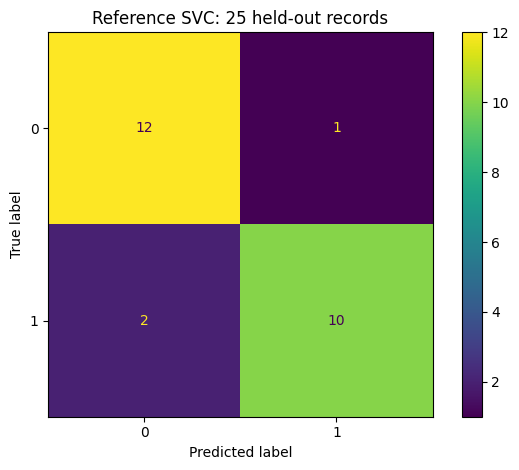

Measure,Value
Macro F1,0.266667
Micro F1,0.333333
Weighted F1,0.266667
Macro precision,0.222222
Macro recall,0.333333
Separate accuracy example,0.500000


TN, FP, FN, TP: [0, 2, 1, 1]
Per-class F1: [0.8 0.  0. ]
No positive labels, zero_division=1: 1.0
Multilabel per-label F1: [0.66666667 1.         0.66666667]
              precision    recall  f1-score   support

     class 0       0.50      1.00      0.67         1
     class 1       0.00      0.00      0.00         1
     class 2       1.00      0.67      0.80         3

    accuracy                           0.60         5
   macro avg       0.50      0.56      0.49         5
weighted avg       0.70      0.60      0.61         5

Log loss (columns ham, spam): 0.21616187468057912


In [2]:
tiny_cm=confusion_matrix([0,1,0,1],[1,1,1,0],labels=[0,1])
print('TN, FP, FN, TP:',tiny_cm.ravel().tolist())
X_syn,y_syn=make_classification(random_state=0)
xs_train,xs_test,ys_train,ys_test=train_test_split(X_syn,y_syn,random_state=0)
svc=SVC(random_state=0).fit(xs_train,ys_train)
svc_cm=confusion_matrix(ys_test,svc.predict(xs_test))
ConfusionMatrixDisplay(svc_cm).plot();plt.title('Reference SVC: 25 held-out records');plt.tight_layout();plt.show()
yt=[0,1,2,0,1,2];yp=[0,2,1,0,0,1]
classification={'Macro F1':f1_score(yt,yp,average='macro'),'Micro F1':f1_score(yt,yp,average='micro'),'Weighted F1':f1_score(yt,yp,average='weighted'),'Macro precision':precision_score(yt,yp,average='macro'),'Macro recall':recall_score(yt,yp,average='macro'),'Separate accuracy example':accuracy_score([0,1,2,3],[0,2,1,3])}
display(pd.DataFrame(classification.items(),columns=['Measure','Value']))
print('Per-class F1:',f1_score(yt,yp,average=None))
print('No positive labels, zero_division=1:',f1_score([0]*6,[0]*6,zero_division=1))
print('Multilabel per-label F1:',f1_score([[0,0,0],[1,1,1],[0,1,1]],[[0,0,0],[1,1,1],[1,1,0]],average=None))
print(classification_report([0,1,2,2,2],[0,0,2,2,1],target_names=['class 0','class 1','class 2'],zero_division=0))
reference_logloss=log_loss(['spam','ham','ham','spam'],[[.1,.9],[.9,.1],[.8,.2],[.35,.65]],labels=['ham','spam'])
print('Log loss (columns ham, spam):',reference_logloss)
summary.update(classification=classification,tiny_cm=tiny_cm.tolist(),svc_cm=svc_cm.tolist(),log_loss=reference_logloss)


The all-zero binary example has no positive cases, so positive-class F1 is undefined. Setting `zero_division=1` substitutes a value of one; it is not evidence that positive cases can be detected. Log loss evaluates probabilities, penalising confident errors more strongly than less confident errors. Its class-column order must agree with the labels.

## ROC and AUC reference calculations

The breast-cancer and Iris logistic examples fit and score the complete dataset. Their AUCs are resubstitution scores, not estimates on unseen records. Breast-cancer label 1 denotes benign and label 0 malignant, so the original positive-class score ranks benign cases. This is a benchmark calculation, not a clinical validation.

The original multiclass `liblinear` behaviour is represented explicitly with `OneVsRestClassifier`, retaining one binary logistic model per Iris class. The solver is given a larger iteration limit to allow convergence. The noisy Iris SVC retains the original 50% hold-out split and 800 additional Gaussian features.

Evaluation,AUC
"Breast cancer logistic, training data",0.994741
"Iris logistic OvR, training data",0.991333
Noisy Iris held-out: setosa,0.912698
Noisy Iris held-out: versicolor,0.603704
Noisy Iris held-out: virginica,0.786765
Noisy Iris held-out: macro,0.767722
Noisy Iris held-out: micro,0.727733


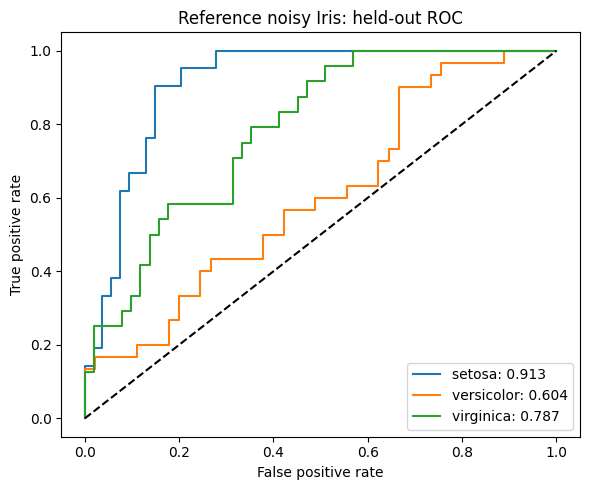

In [3]:
bc=load_breast_cancer();iris=load_iris()
bc_full=LogisticRegression(solver='liblinear',random_state=0,max_iter=10000).fit(bc.data,bc.target)
bc_auc=roc_auc_score(bc.target,bc_full.predict_proba(bc.data)[:,1])
iris_full=OneVsRestClassifier(LogisticRegression(solver='liblinear',max_iter=10000)).fit(iris.data,iris.target)
iris_auc=roc_auc_score(iris.target,iris_full.predict_proba(iris.data),multi_class='ovr')
Y=label_binarize(iris.target,classes=[0,1,2])
rng=np.random.RandomState(0)
noise=rng.randn(len(Y),800)
train_idx,test_idx=train_test_split(np.arange(len(Y)),test_size=.5,random_state=0)
X_noisy=np.c_[iris.data,noise]
original_svc=OneVsRestClassifier(SVC(kernel='linear',probability=True,random_state=rng))
reference_scores=original_svc.fit(X_noisy[train_idx],Y[train_idx]).decision_function(X_noisy[test_idx])
reference_class_auc=roc_auc_score(Y[test_idx],reference_scores,average=None)
reference_micro=roc_auc_score(Y[test_idx],reference_scores,average='micro')
display(pd.DataFrame([['Breast cancer logistic, training data',bc_auc],['Iris logistic OvR, training data',iris_auc],*[[f'Noisy Iris held-out: {name}',v] for name,v in zip(iris.target_names,reference_class_auc)],['Noisy Iris held-out: macro',reference_class_auc.mean()],['Noisy Iris held-out: micro',reference_micro]],columns=['Evaluation','AUC']))
fig,ax=plt.subplots(figsize=(6,5))
for i,name in enumerate(iris.target_names):
    fpr,tpr,_=roc_curve(Y[test_idx,i],reference_scores[:,i]);ax.plot(fpr,tpr,label=f'{name}: {reference_class_auc[i]:.3f}')
ax.plot([0,1],[0,1],'k--');ax.set(xlabel='False positive rate',ylabel='True positive rate',title='Reference noisy Iris: held-out ROC');ax.legend();plt.tight_layout();plt.show()
summary.update(bc_auc=bc_auc,iris_auc=iris_auc,iris_class_auc=reference_class_auc.tolist(),iris_macro=float(reference_class_auc.mean()),iris_micro=reference_micro)


## Controlled AUC experiments

Every Iris comparison uses the same 75 training and 75 evaluation records. Noise columns come from the same fixed 800-column matrix, taking a prefix for smaller feature counts. First, the number of irrelevant features changes at C = 1. Next, C changes with all 800 noise features retained. Larger C reduces the strength of regularisation. Scores use one-versus-rest decision values, not predicted labels. Probability fitting is disabled in these comparisons because ROC uses decision scores; the C = 1, 800-feature result is checked against the reference.

These repeated comparisons make the hold-out set exploratory validation data. They do not provide an untouched final test estimate for a selected configuration. A single noise draw and split cannot establish a universal effect.

Noise features,C,Setosa AUC,Versicolor AUC,Virginica AUC,Macro AUC,Micro AUC
0,1,1.000000,0.721481,0.995098,0.905527,0.939022
20,1,1.000000,0.660741,0.906046,0.855595,0.866844
200,1,0.998236,0.637778,0.829248,0.821754,0.813067
800,1,0.912698,0.603704,0.786765,0.767722,0.727733


Noise features,C,Setosa AUC,Versicolor AUC,Virginica AUC,Macro AUC,Micro AUC
800,0.001,0.912698,0.589630,0.756536,0.752955,0.661244
800,0.010,0.912698,0.603704,0.786765,0.767722,0.727733
800,0.100,0.912698,0.603704,0.786765,0.767722,0.727733
800,1.000,0.912698,0.603704,0.786765,0.767722,0.727733
800,10.000,0.912698,0.603704,0.786765,0.767722,0.727733


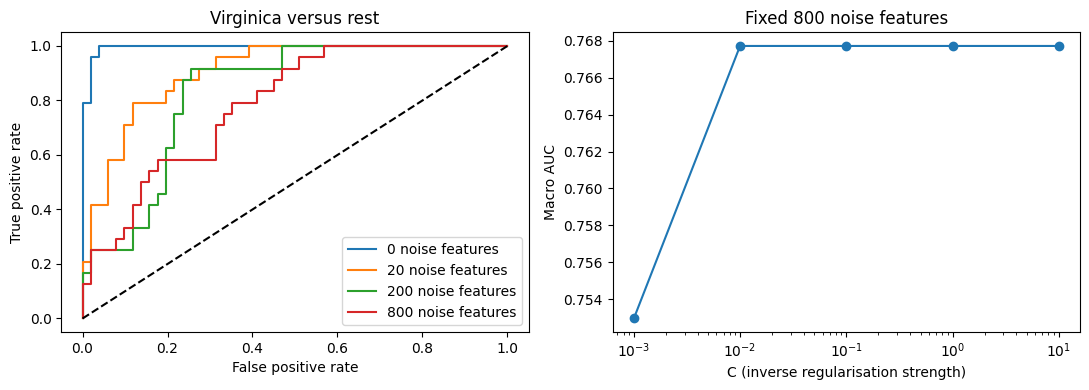

In [4]:
def measure_iris(noise_count,C):
    features=np.c_[iris.data,noise[:,:noise_count]]
    model=OneVsRestClassifier(SVC(kernel='linear',C=C,random_state=0))
    scores=model.fit(features[train_idx],Y[train_idx]).decision_function(features[test_idx])
    per_class=roc_auc_score(Y[test_idx],scores,average=None)
    return {'Noise features':noise_count,'C':C,'Setosa AUC':per_class[0],'Versicolor AUC':per_class[1],'Virginica AUC':per_class[2],'Macro AUC':per_class.mean(),'Micro AUC':roc_auc_score(Y[test_idx],scores,average='micro')},scores
noise_results=[];score_sets={}
for n in [0,20,200,800]:
    row,scores=measure_iris(n,1);noise_results.append(row);score_sets[n]=scores
c_results=[measure_iris(800,c)[0] for c in [.001,.01,.1,1,10]]
assert np.isclose(noise_results[-1]['Macro AUC'],reference_class_auc.mean())
display(pd.DataFrame(noise_results).round(6));display(pd.DataFrame(c_results).round(6))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for n,scores in score_sets.items():
    fpr,tpr,_=roc_curve(Y[test_idx,2],scores[:,2]);axes[0].plot(fpr,tpr,label=f'{n} noise features')
axes[0].plot([0,1],[0,1],'k--');axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Virginica versus rest');axes[0].legend()
axes[1].semilogx([v['C'] for v in c_results],[v['Macro AUC'] for v in c_results],marker='o');axes[1].set(xlabel='C (inverse regularisation strength)',ylabel='Macro AUC',title='Fixed 800 noise features');plt.tight_layout();plt.show()
summary.update(noise=noise_results,c_values=c_results)


## Decision thresholds versus AUC

A separate breast-cancer comparison uses a stratified 70:30 split (seed 0) and standardisation fitted only to the training records. One logistic model is evaluated at three thresholds. Changing the threshold changes decisions, precision and recall, but does not change the AUC of its unchanged probability scores. The positive class remains benign. Thresholds are illustrative, not deployment recommendations.

In [5]:
xb_train,xb_eval,yb_train,yb_eval=train_test_split(bc.data,bc.target,test_size=.3,stratify=bc.target,random_state=0)
binary=make_pipeline(StandardScaler(),LogisticRegression(solver='liblinear',random_state=0,max_iter=10000)).fit(xb_train,yb_train)
prob=binary.predict_proba(xb_eval)[:,1]
thresholds=[]
for threshold in [.2,.5,.8]:
    prediction=prob>=threshold
    thresholds.append({'Threshold':threshold,'Accuracy':accuracy_score(yb_eval,prediction),'Benign precision':precision_score(yb_eval,prediction),'Benign recall':recall_score(yb_eval,prediction),'Score AUC':roc_auc_score(yb_eval,prob)})
display(pd.DataFrame(thresholds).round(6))
assert len(set(row['Score AUC'] for row in thresholds))==1
summary['thresholds']=thresholds


Threshold,Accuracy,Benign precision,Benign recall,Score AUC
0.2,0.964912,0.946903,1.000000,0.995619
0.5,0.959064,0.971698,0.962617,0.995619
0.8,0.947368,0.980392,0.934579,0.995619


## Regression reference calculations and residual experiments

Observed targets are [3, −0.5, 2, 7]; reference predictions are [2.5, 0, 2, 8]. The source heading says RMSE, but its call to `mean_squared_error` returns MSE. Both are reported explicitly here. R² = 1 − SSE/SST, where SST is the squared deviation of targets from their mean. R² is a score, not an error metric: one is perfect, zero matches the observed-mean predictor, and negative values indicate a worse squared-error fit than that comparator.

Residual scaling uses prediction = target + k × (reference prediction − target). This isolates error magnitude without fitting a regression model. Additional controls use the observed mean, add a constant bias, and rescale both targets and predictions into different units. The observed-mean comparator is an algebraic reference, not a deployable estimator fitted to an independent training set.

Scenario,MSE,RMSE,MAE,R2
Residual scale 0,0.00000,0.000000,0.00,1.000000
Residual scale 0.5,0.09375,0.306186,0.25,0.987152
Residual scale 1,0.37500,0.612372,0.50,0.948608
Residual scale 2,1.50000,1.224745,1.00,0.794433
Residual scale 4,6.00000,2.449490,2.00,0.177730
Residual scale 8,24.00000,4.898979,4.00,-2.289079


Scenario,MSE,RMSE,MAE,R2
Observed-mean predictor,7.296875,2.701273,2.125,0.000000
Reference predictions + 2,5.375000,2.318405,2.250,0.263383
Both arrays multiplied by 10,37.500000,6.123724,5.000,0.948608


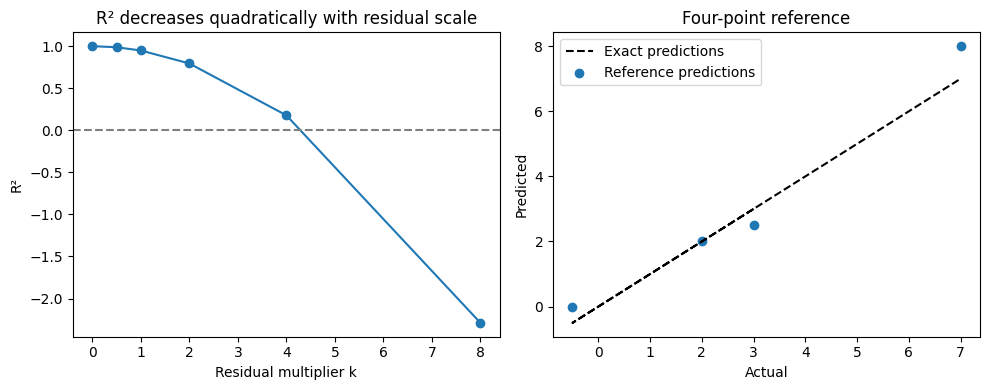

SSE: 1.5 SST: 29.1875 R2: 0.9486081370449679


In [6]:
actual=np.array([3,-.5,2,7.]);reference=np.array([2.5,0,2,8.])
def regression_row(label,predicted,observed=actual):
    mse=mean_squared_error(observed,predicted)
    return {'Scenario':label,'MSE':mse,'RMSE':float(np.sqrt(mse)),'MAE':mean_absolute_error(observed,predicted),'R2':r2_score(observed,predicted)}
regression=[dict(regression_row(f'Residual scale {k:g}',actual+k*(reference-actual)),k=k) for k in [0,.5,1,2,4,8]]
controls=[regression_row('Observed-mean predictor',np.full(4,actual.mean())),regression_row('Reference predictions + 2',reference+2),regression_row('Both arrays multiplied by 10',reference*10,actual*10)]
display(pd.DataFrame(regression).drop(columns='k').round(6));display(pd.DataFrame(controls).round(6))
sse=float(np.sum((actual-reference)**2));sst=float(np.sum((actual-actual.mean())**2))
print('SSE:',sse,'SST:',sst,'R2:',1-sse/sst)
for row in regression:
    assert np.isclose(row['R2'],1-row['k']**2*sse/sst)
assert np.isclose(controls[0]['R2'],0)
assert np.isclose(controls[2]['R2'],regression[2]['R2'])
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot([v['k'] for v in regression],[v['R2'] for v in regression],marker='o');axes[0].axhline(0,color='grey',linestyle='--');axes[0].set(xlabel='Residual multiplier k',ylabel='R²',title='R² decreases quadratically with residual scale')
axes[1].plot(actual,actual,'k--',label='Exact predictions');axes[1].scatter(actual,reference,label='Reference predictions');axes[1].set(xlabel='Actual',ylabel='Predicted',title='Four-point reference');axes[1].legend();plt.tight_layout();plt.show()
summary.update(regression=regression,controls=controls,sse=sse,sst=sst)


## Interpretation and limitations

On the fixed Iris split, increasing noise features from zero to 800 reduced macro AUC from 0.905527 to 0.767722. At 800 noise features, C values from 0.01 to 10 produced identical AUCs. Binary score AUC remained 0.995619 at all three thresholds. Regression R² fell from 0.948608 at the reference residuals to −2.289079 at eight times those residuals. These are observations from the executed comparisons, not universal parameter recommendations.

AUC concerns ordering across thresholds, whereas precision and recall describe a particular decision rule (Fawcett, 2006). Precision–recall analysis is especially useful when the positive class is rare (Saito and Rehmsmeier, 2015). Neither metric alone establishes calibration, acceptable error costs or fairness across groups.

R² adds a variance-relative comparison to absolute errors (Chicco, Warrens and Jurman, 2021), but it should be interpreted alongside MAE or RMSE in meaningful units. Four fixed observations demonstrate metric behaviour; they cannot establish generalisation or causality. Constant targets require special treatment because their SST is zero.

Legal questions include permitted data use, privacy and discriminatory outcomes. Responsible reporting makes the positive class, split, averaging rule and evaluation population explicit. Repeatedly selecting models against one hold-out set weakens its independence. Before deployment, evaluation should include representative data, relevant subgroup errors, privacy safeguards and a documented process for reviewing harmful decisions.

## Provenance

Adapted from `Unit11_model_Performance_Measurement.ipynb`. The reference arrays, synthetic SVC and noisy Iris setup are retained. Explicit multiclass wrapping provides compatibility with current scikit-learn; the misleading RMSE heading is corrected. Added experiments use fixed splits and controlled parameter changes. Cells were executed sequentially with outputs embedded. Analysis and editorial preparation used AI assistance.

## References

Chicco, D., Warrens, M.J. and Jurman, G. (2021) ‘The coefficient of determination R-squared is more informative than SMAPE, MAE, MAPE, MSE and RMSE in regression analysis evaluation’, *PeerJ Computer Science*, 7, e623. Available at: https://doi.org/10.7717/peerj-cs.623 (Accessed: 14 October 2026).

Fawcett, T. (2006) ‘An introduction to ROC analysis’, *Pattern Recognition Letters*, 27(8), pp. 861–874. Available at: https://doi.org/10.1016/j.patrec.2005.10.010 (Accessed: 14 October 2026).

Saito, T. and Rehmsmeier, M. (2015) ‘The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets’, *PLOS ONE*, 10(3), e0118432. Available at: https://doi.org/10.1371/journal.pone.0118432 (Accessed: 14 October 2026).